In [2]:
from google.colab import files
uploaded = files.upload()

Saving Dataset .csv to Dataset .csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('Dataset .csv')
geo_df = df[(df['Latitude'] != 0) & (df['Longitude'] != 0)].copy()
geo_df.head(2)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591


In [4]:
city_stats = geo_df.groupby('City').agg(
    Total_Restaurants=('Restaurant ID', 'count'),
    Avg_Rating=('Aggregate rating', 'mean'),
    Avg_Price_Range=('Price range', 'mean'),
    Avg_Cost=('Average Cost for two', 'mean')
).sort_values(by='Total_Restaurants', ascending=False)
print("=== Top 10 Cities by Restaurant Count ===")
display(city_stats.head(10))

=== Top 10 Cities by Restaurant Count ===


,Total_Restaurants,Avg_Rating,Avg_Price_Range,Avg_Cost
City,,,,
New Delhi,5240,2.502061,1.632443,603.948473
Gurgaon,1070,2.721963,1.881308,729.205607
Noida,986,2.165112,1.627789,551.521298
Faridabad,229,1.991703,1.475983,451.310044
Ghaziabad,25,2.852000,1.800000,602.000000
Ahmedabad,21,4.161905,2.571429,857.142857
Augusta,20,4.130000,2.150000,27.000000
Cedar Rapids/Iowa City,20,4.165000,2.050000,25.750000
Chennai,20,4.315000,2.450000,1085.000000


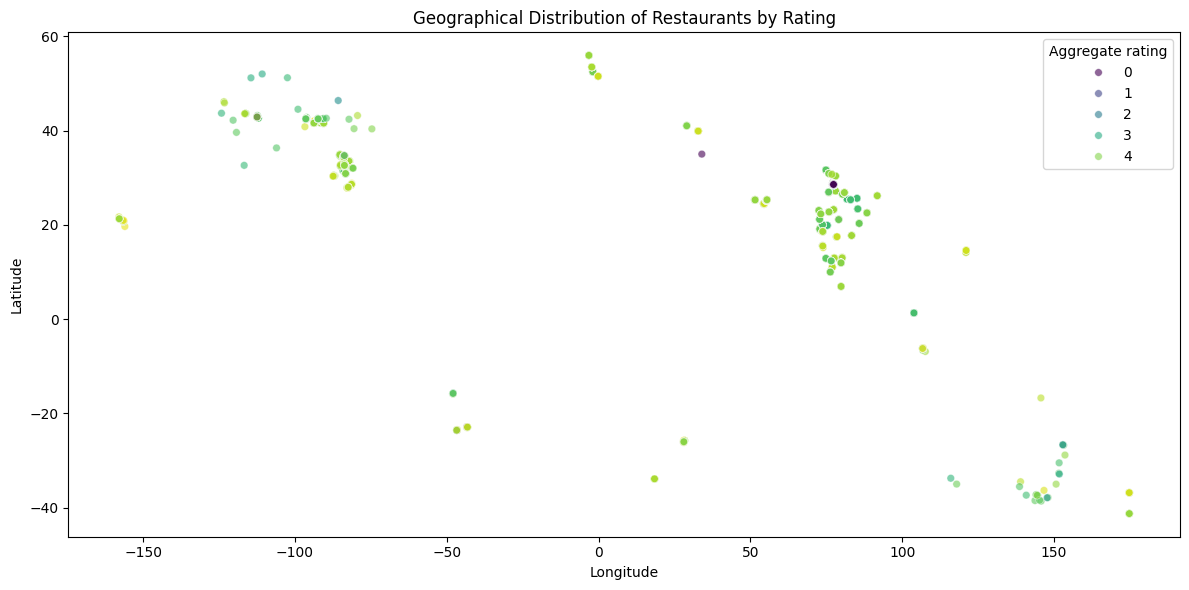

/tmp/ipykernel_5343/649926845.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=city_stats.head(10).index, y=city_stats.head(10)['Total_Restaurants'], palette='magma')


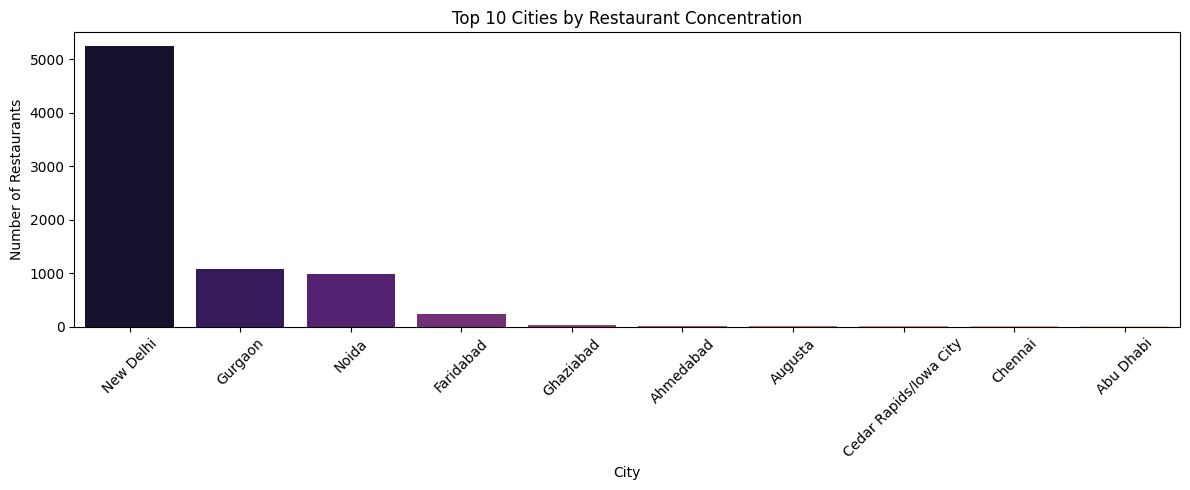

In [5]:
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=geo_df,
    x='Longitude',
    y='Latitude',
    hue='Aggregate rating',
    palette='viridis',
    alpha=0.6,
    s=30
)
plt.title('Geographical Distribution of Restaurants by Rating')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.show()
plt.figure(figsize=(12, 5))
sns.barplot(x=city_stats.head(10).index, y=city_stats.head(10)['Total_Restaurants'], palette='magma')
plt.title('Top 10 Cities by Restaurant Concentration')
plt.xticks(rotation=45)
plt.ylabel('Number of Restaurants')
plt.tight_layout()
plt.show()

In [6]:
top_city = city_stats.index[0]
locality_stats = geo_df[geo_df['City'] == top_city].groupby('Locality').agg(
    Count=('Restaurant ID', 'count'),
    Mean_Rating=('Aggregate rating', 'mean')
).sort_values(by='Count', ascending=False)
print(f"=== Top 10 Localities in {top_city} ===")
display(locality_stats.head(10))
print("\nKey Insights:")
print("1. Maximum restaurant concentration National Capital Region (New Delhi, Gurgaon, Noida) lo undhi.")
print("2. Prime commercial areas lo aggregate rating 4.0+ ekkuvaga undhi compared to outer areas.")

=== Top 10 Localities in New Delhi ===


,Count,Mean_Rating
Locality,,
Connaught Place,122,3.686885
Rajouri Garden,98,3.589796
Defence Colony,85,3.208235
Malviya Nagar,84,3.417857
Pitampura,83,2.853012
Shahdara,81,1.518519
Rajinder Nagar,79,3.017722
Satyaniketan,75,3.494667
Karol Bagh,75,3.065333



Key Insights:
1. Maximum restaurant concentration National Capital Region (New Delhi, Gurgaon, Noida) lo undhi.
2. Prime commercial areas lo aggregate rating 4.0+ ekkuvaga undhi compared to outer areas.
